# TrpB: does adding a biological profile improve the calibrated landscape?

**The changes are mixed.** The alignment-profile prior brings the median walk length and pooled high-order epistasis closer to the measured TrpB landscape at the previously highlighted setting. It moves several local epistasis measures farther away, and favorable medians do not translate into consistent improvements across individual seeds.

This notebook compares completed **RUN-178 (Profile)** with recorded **RUN-175 (Synthetic)** under EXP-065. It rebuilds every figure and comparison table from the frozen run outputs, without rerunning calibration or the synthetic control. `validation.ipynb` separately reproduces the numerical and provenance checks.

The only scientific input change was the additive prior: published alignment-derived amino-acid frequencies at four TrpB sites replaced random additive effects. Both versions retain synthetic interactions. All global readout parameters were refitted with the original procedure, including the inherited endpoint fits. Seeds, masks, cube geometries, observation assignments, fitting budgets and diagnostic definitions were retained. The comparison concerns the prior **after the same calibration procedure**, not a prior swap at fixed readout parameters.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import os
os.environ.setdefault('MPLBACKEND', 'Agg')
os.environ.setdefault('MPLCONFIGDIR', '/tmp/ana070-matplotlib')
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'AIM.md').exists())
ANA = ROOT / 'analyses/2026-11-19_ANA-070_run-178-trpb-profile-prior-versus-synthetic-control'
sys.path.insert(0, str(ANA / 'notebooks'))
import pandas as pd
from IPython.display import Image, display
import data_tools as analysis
import plot_tools as plots
for prior, bundle in analysis.BUNDLES.items():
    manifest = json.loads((bundle / 'outputs/manifest.json').read_text())
    for relative, digest in manifest['files'].items():
        assert hashlib.sha256((bundle / 'outputs' / relative).read_bytes()).hexdigest() == digest
print('Both frozen output manifests verified. No calibration or simulation is run here.')

Both frozen output manifests verified. No calibration or simulation is run here.


## Read the figures

Blue is the synthetic prior, orange is the profile prior, and black marks measured TrpB. The main comparison uses the **eight generator seeds withheld from calibration**, with the same seeds paired across priors. They are fresh relative to fitting, not new biological replicates. The other 16 seeds remain visible in the sensitivity figure and tables.

The inherited reference is interaction strength **r = 0.5**, the **shared-stop observation sensitivity**, and a resolution of **0.001 × the empirical calibration range**. It was highlighted in the earlier control analysis; it was not selected to favor the new profile results. All six strengths and all three observation models remain in the figures. Shaded ranges show the 10th–90th percentiles of seed outcomes, **not confidence intervals**.

In [2]:
data, fits, latent = analysis.load()
aggregate, paired_summary, inherited = analysis.make_tables(data, fits, latent)
display(pd.DataFrame([
    {'Prior': prior, 'Run': bundle.name, 'Calibration settings': 18, 'Evaluation seeds': 24,
     'Fresh / reused': '8 / 16', 'Measured genotypes': 159129}
    for prior, bundle in analysis.BUNDLES.items()
]))

,Prior,Run,Calibration settings,Evaluation seeds,Fresh / reused,Measured genotypes
0,Synthetic,RUN-175,18,24,8 / 16,159129
1,Profile,RUN-178,18,24,8 / 16,159129


## Figure 1 — A closer median can conceal worse individual outcomes

Each thin line joins the same generator seed under the two priors. The black horizontal reference is the measured descriptor; closeness to it is the comparison of interest. Thick marks summarize the seed median. “Closer” counts paired seeds with smaller absolute error, not seeds on a preferred side of the target. A 1e-10 tolerance only distinguishes numerical ties; it is not a scientific acceptance threshold.

At this inherited setting, median walk length changes **7.46 → 8.75 substitutions**, against **8.59** measured. Yet only **2/8** paired seeds have a smaller walk-length error. Pooled high-order power fraction changes **0.176 → 0.087**, against **0.086**, with **4/8** seeds closer. Equal-cube epistasis, sign epistasis and the median diminishing-returns slope have worse median agreement. Top-1% success changes **71.4% → 76.3%**, against **65.0%** measured.

A walk starts uniformly over measured genotypes and repeatedly chooses uniformly among improving neighbors. Its length and probability of reaching its own landscape's top 1% are exact graph expectations, not sampled walks. This does not ask whether the same empirical genotype is recovered.

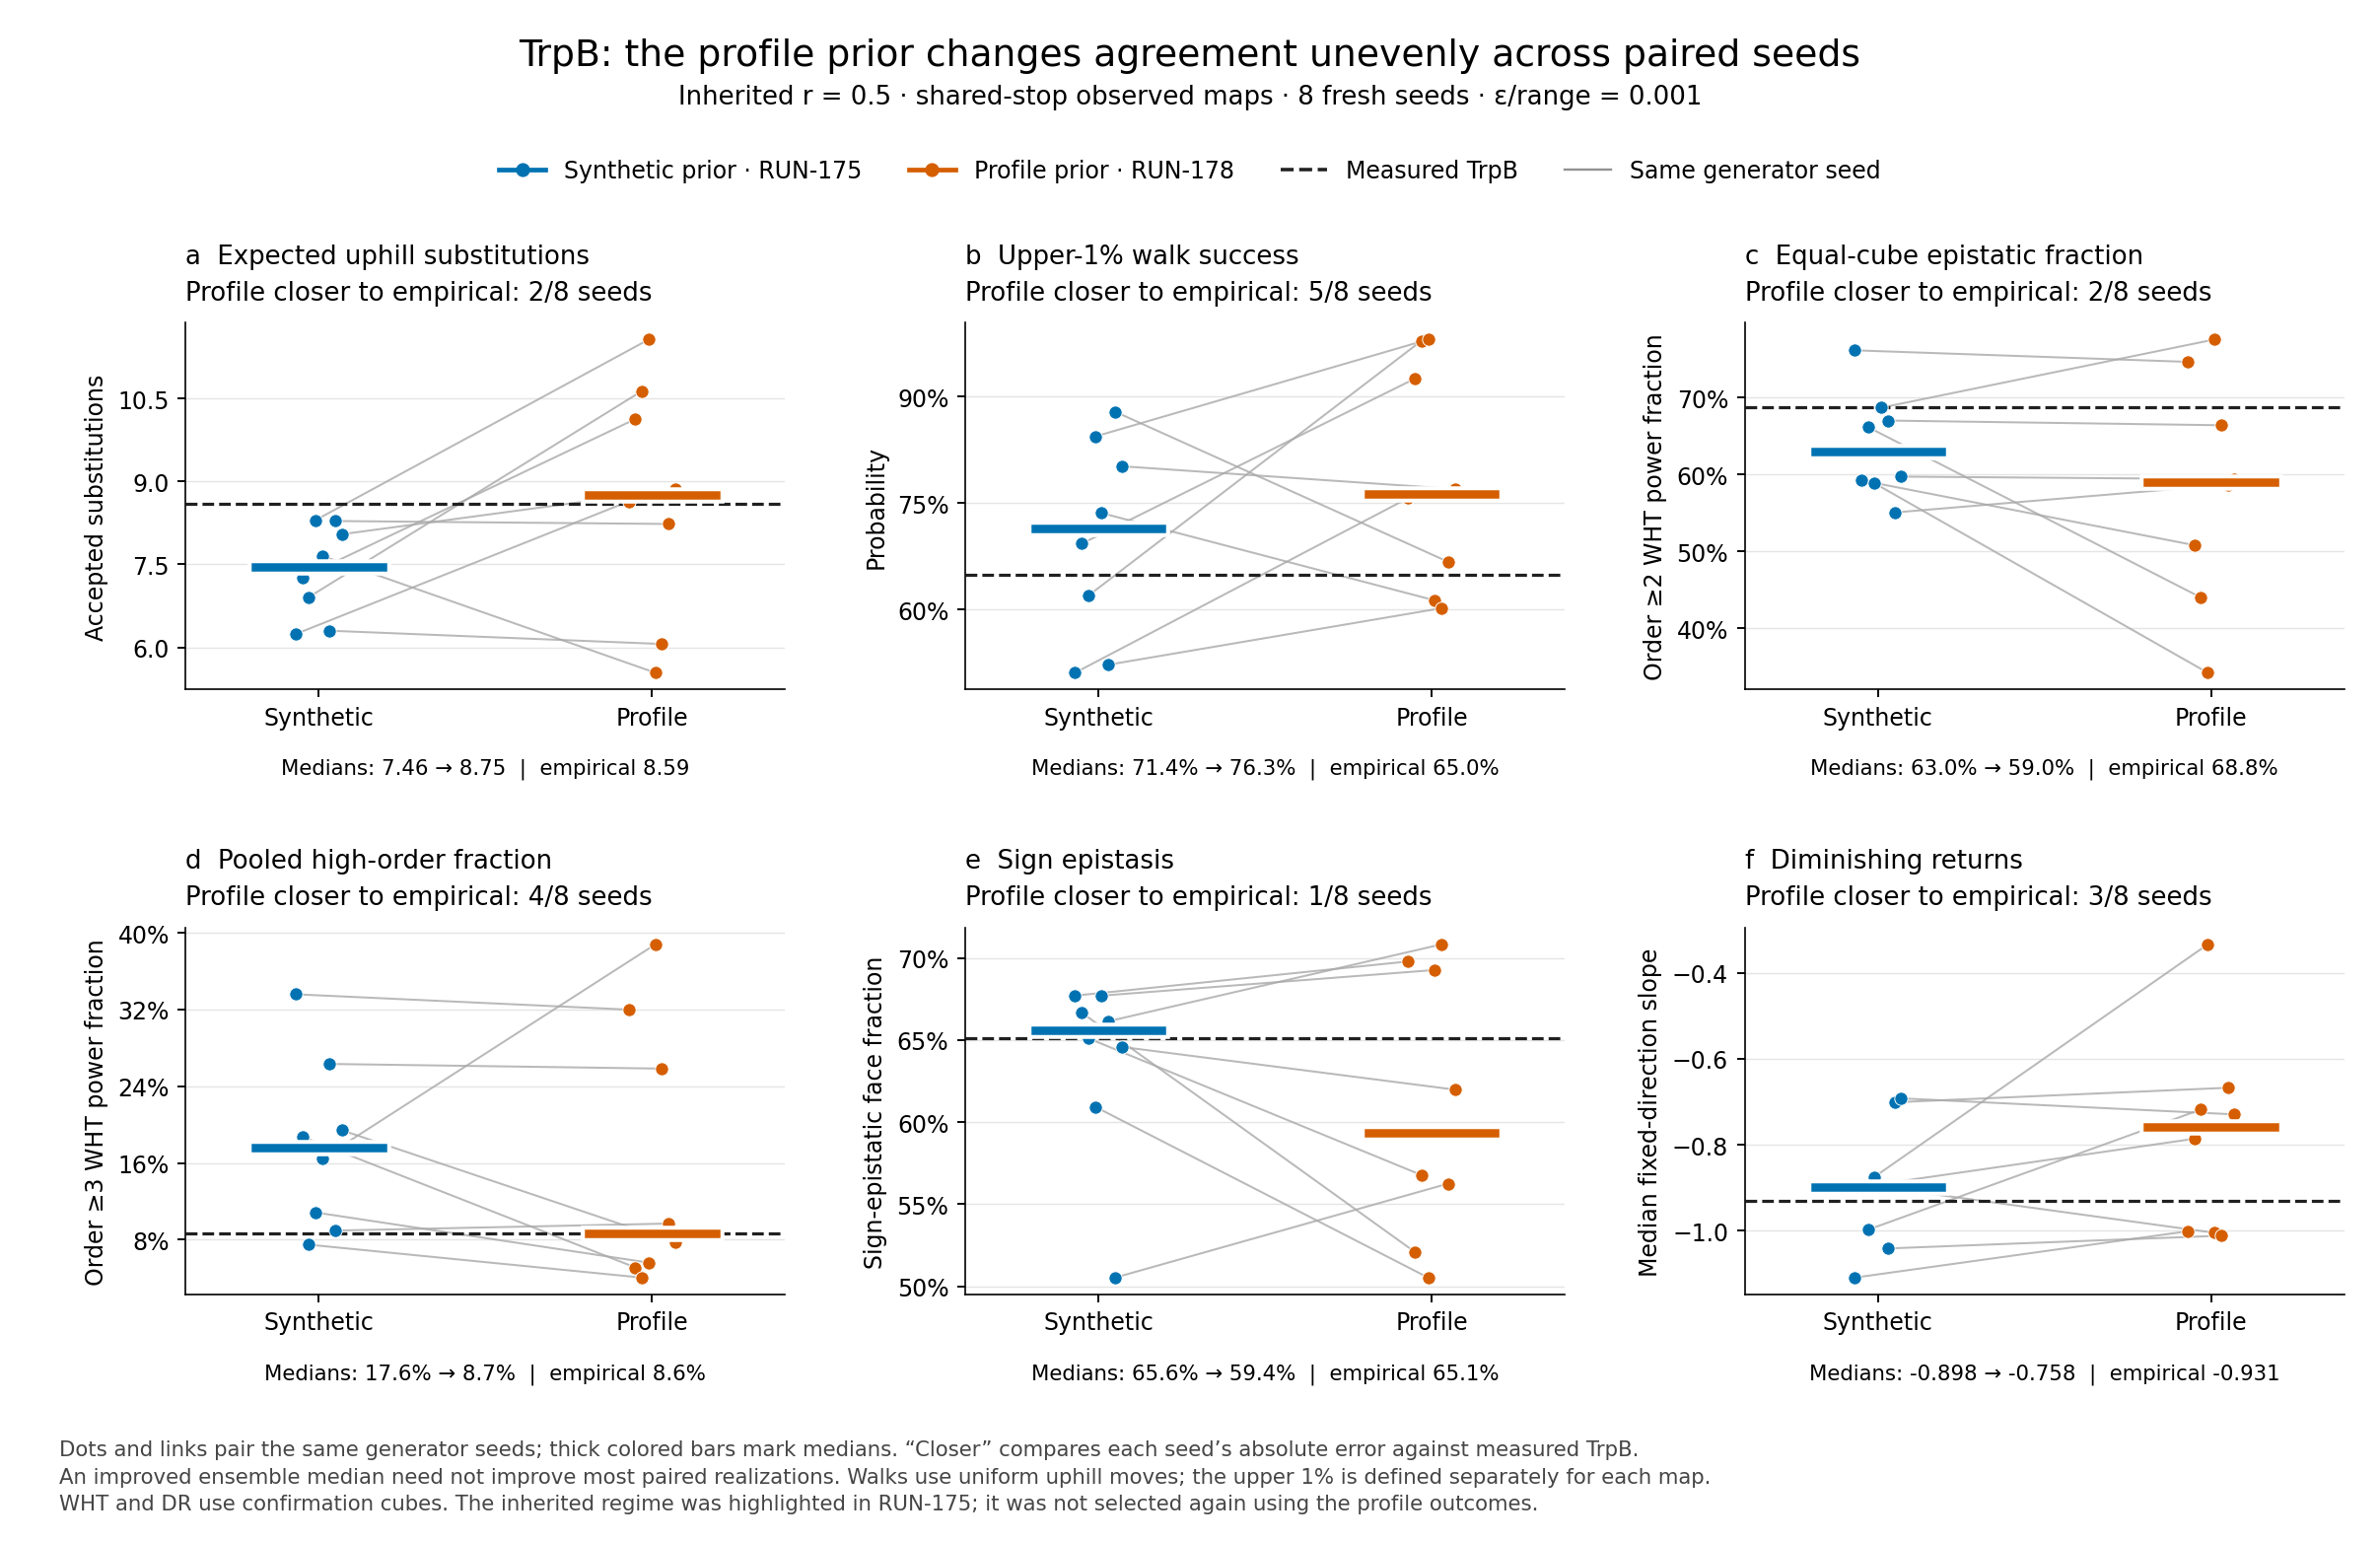

In [3]:
display(Image(filename=str(plots.paired_reference(data, analysis.FIGURES))))

## Figure 2 — The interaction sweep retains a trade-off

At higher interaction strength, profile landscapes regain more equal-cube epistasis and a more negative diminishing-returns slope, while their walks become shorter and top-1% success remains above the measured value. No strength improves every descriptor. Both priors' seed ranges are shown so that a close median is not mistaken for robust agreement.

**Equal-cube power fractions** gives each resolvable local cube equal weight. **Pooled power fractions** weights cubes by their nonconstant fitness variation. These answer different questions; the profile can improve the pooled statistic while worsening the typical local-cube statistic. Fractions divide the specified interaction-order power by total nonconstant power. “High-order” means interaction order three or four. Sign epistasis means that a mutation effect changes sign with background. A negative diminishing-returns slope means a mutation tends to have a smaller effect on fitter backgrounds. These epistasis and graph diagnostics were not fitted.

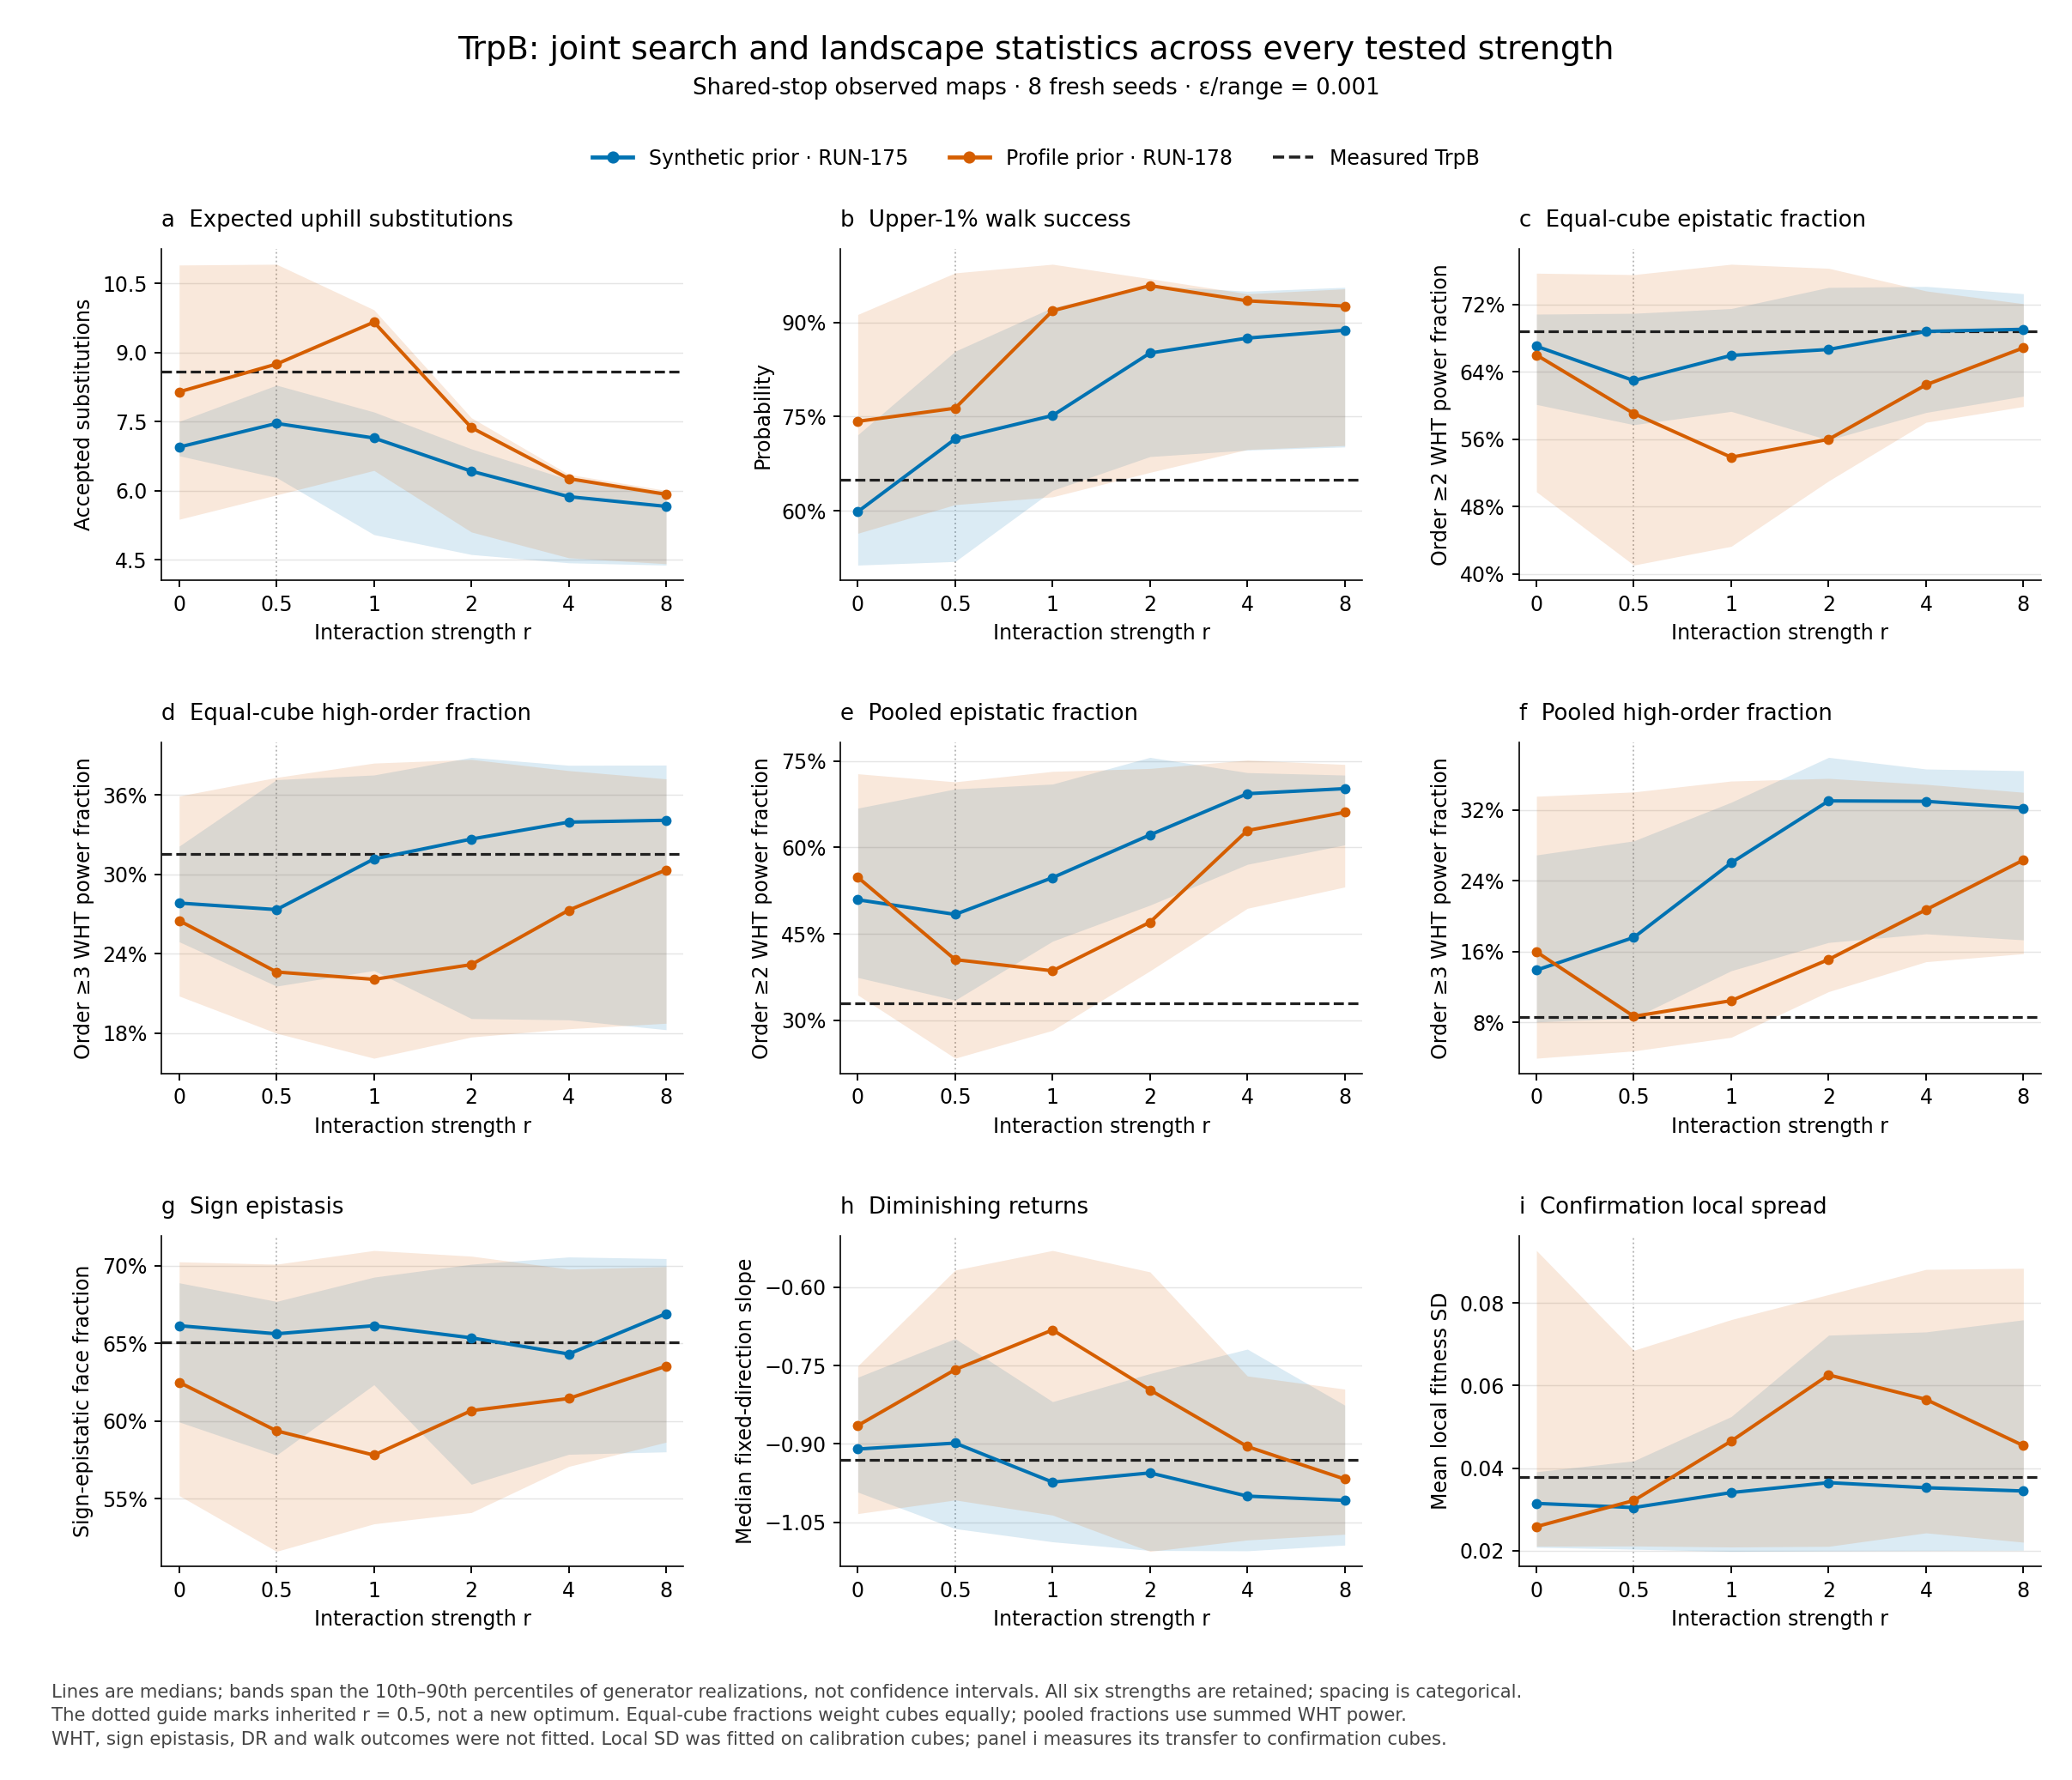

In [4]:
display(Image(filename=str(plots.sweep(data, analysis.FIGURES))))

## Figure 3 — The observation assumption still matters

Each column uses a readout separately calibrated under its stated observation assumption; the noise donor model remains frozen. “No added noise” shows intrinsic fitness; the other columns show the observed map, with measurement draws frozen once per genotype. These are three distinct calibration conditions, not noise added to one common fitted curve.

Without added noise, profile top-1% success medians are approximately **95–100%** across the sweep, far above **65%** measured. Shared-stop observations give closer illustrative regimes, but that model is a sensitivity assumption rather than an identified noise mechanism. At **r = 0**, the profile plus shared-stop observations already produces an equal-cube epistatic fraction of **0.660**, against **0.688** measured. Apparent observed epistasis therefore does not uniquely establish intrinsic interactions.

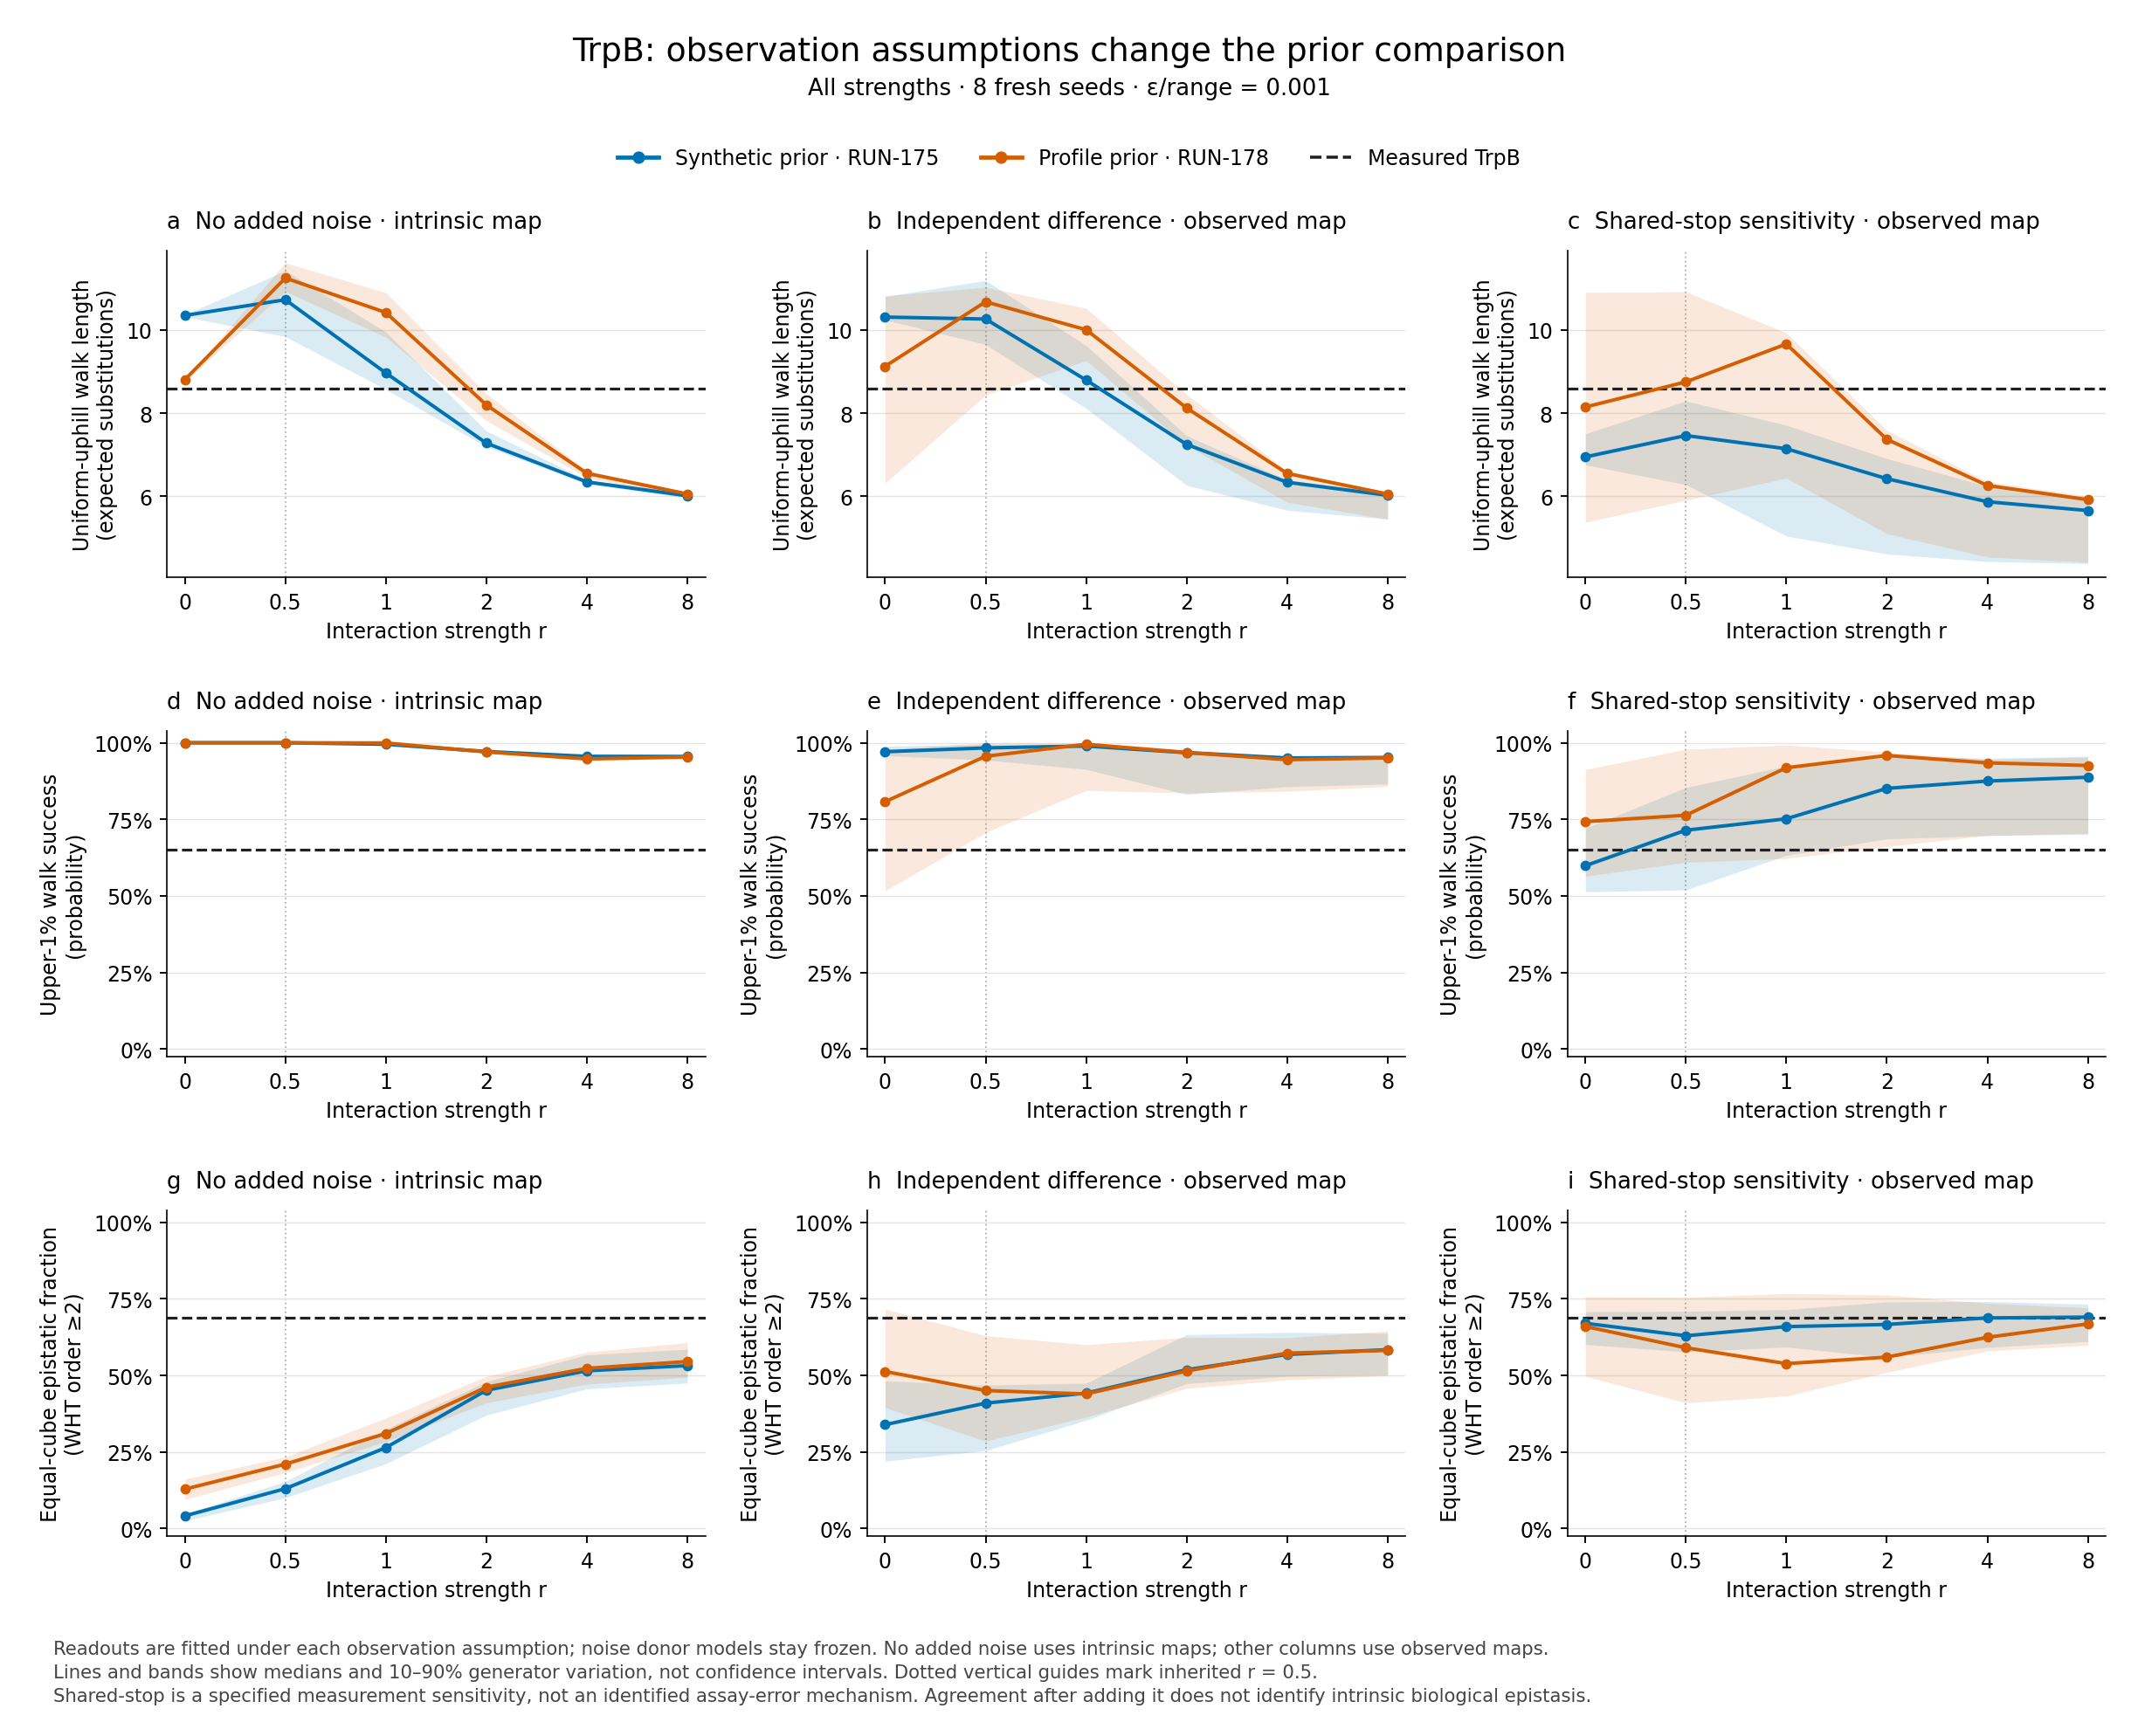

In [5]:
display(Image(filename=str(plots.observation(data, analysis.FIGURES))))

## Figure 4 — Seed cohort and measurement resolution change the comparison

This sensitivity view retains the inherited r = 0.5/shared-stop setting and shows both seed cohorts at all three resolutions. The empirical target is recalculated at the same resolution. Whole-library graph metrics include calibration nodes; they are unfitted descriptors, not a disjoint genotype test. A zero threshold counts any strictly improving step; positive thresholds disregard changes below the stated fraction of the empirical calibration range.

The eight fresh seeds and 16 reused seeds are shown separately rather than pooled into a more reassuring average. For example, profile walk-length medians are **8.75** on fresh seeds but **7.33** on reused seeds at the primary resolution. Neither cohort is a set of independent protein experiments. The tables also retain all strengths, intrinsic maps from noisy calibrations, neutral-component statistics, greedy walks and exact-best outcomes.

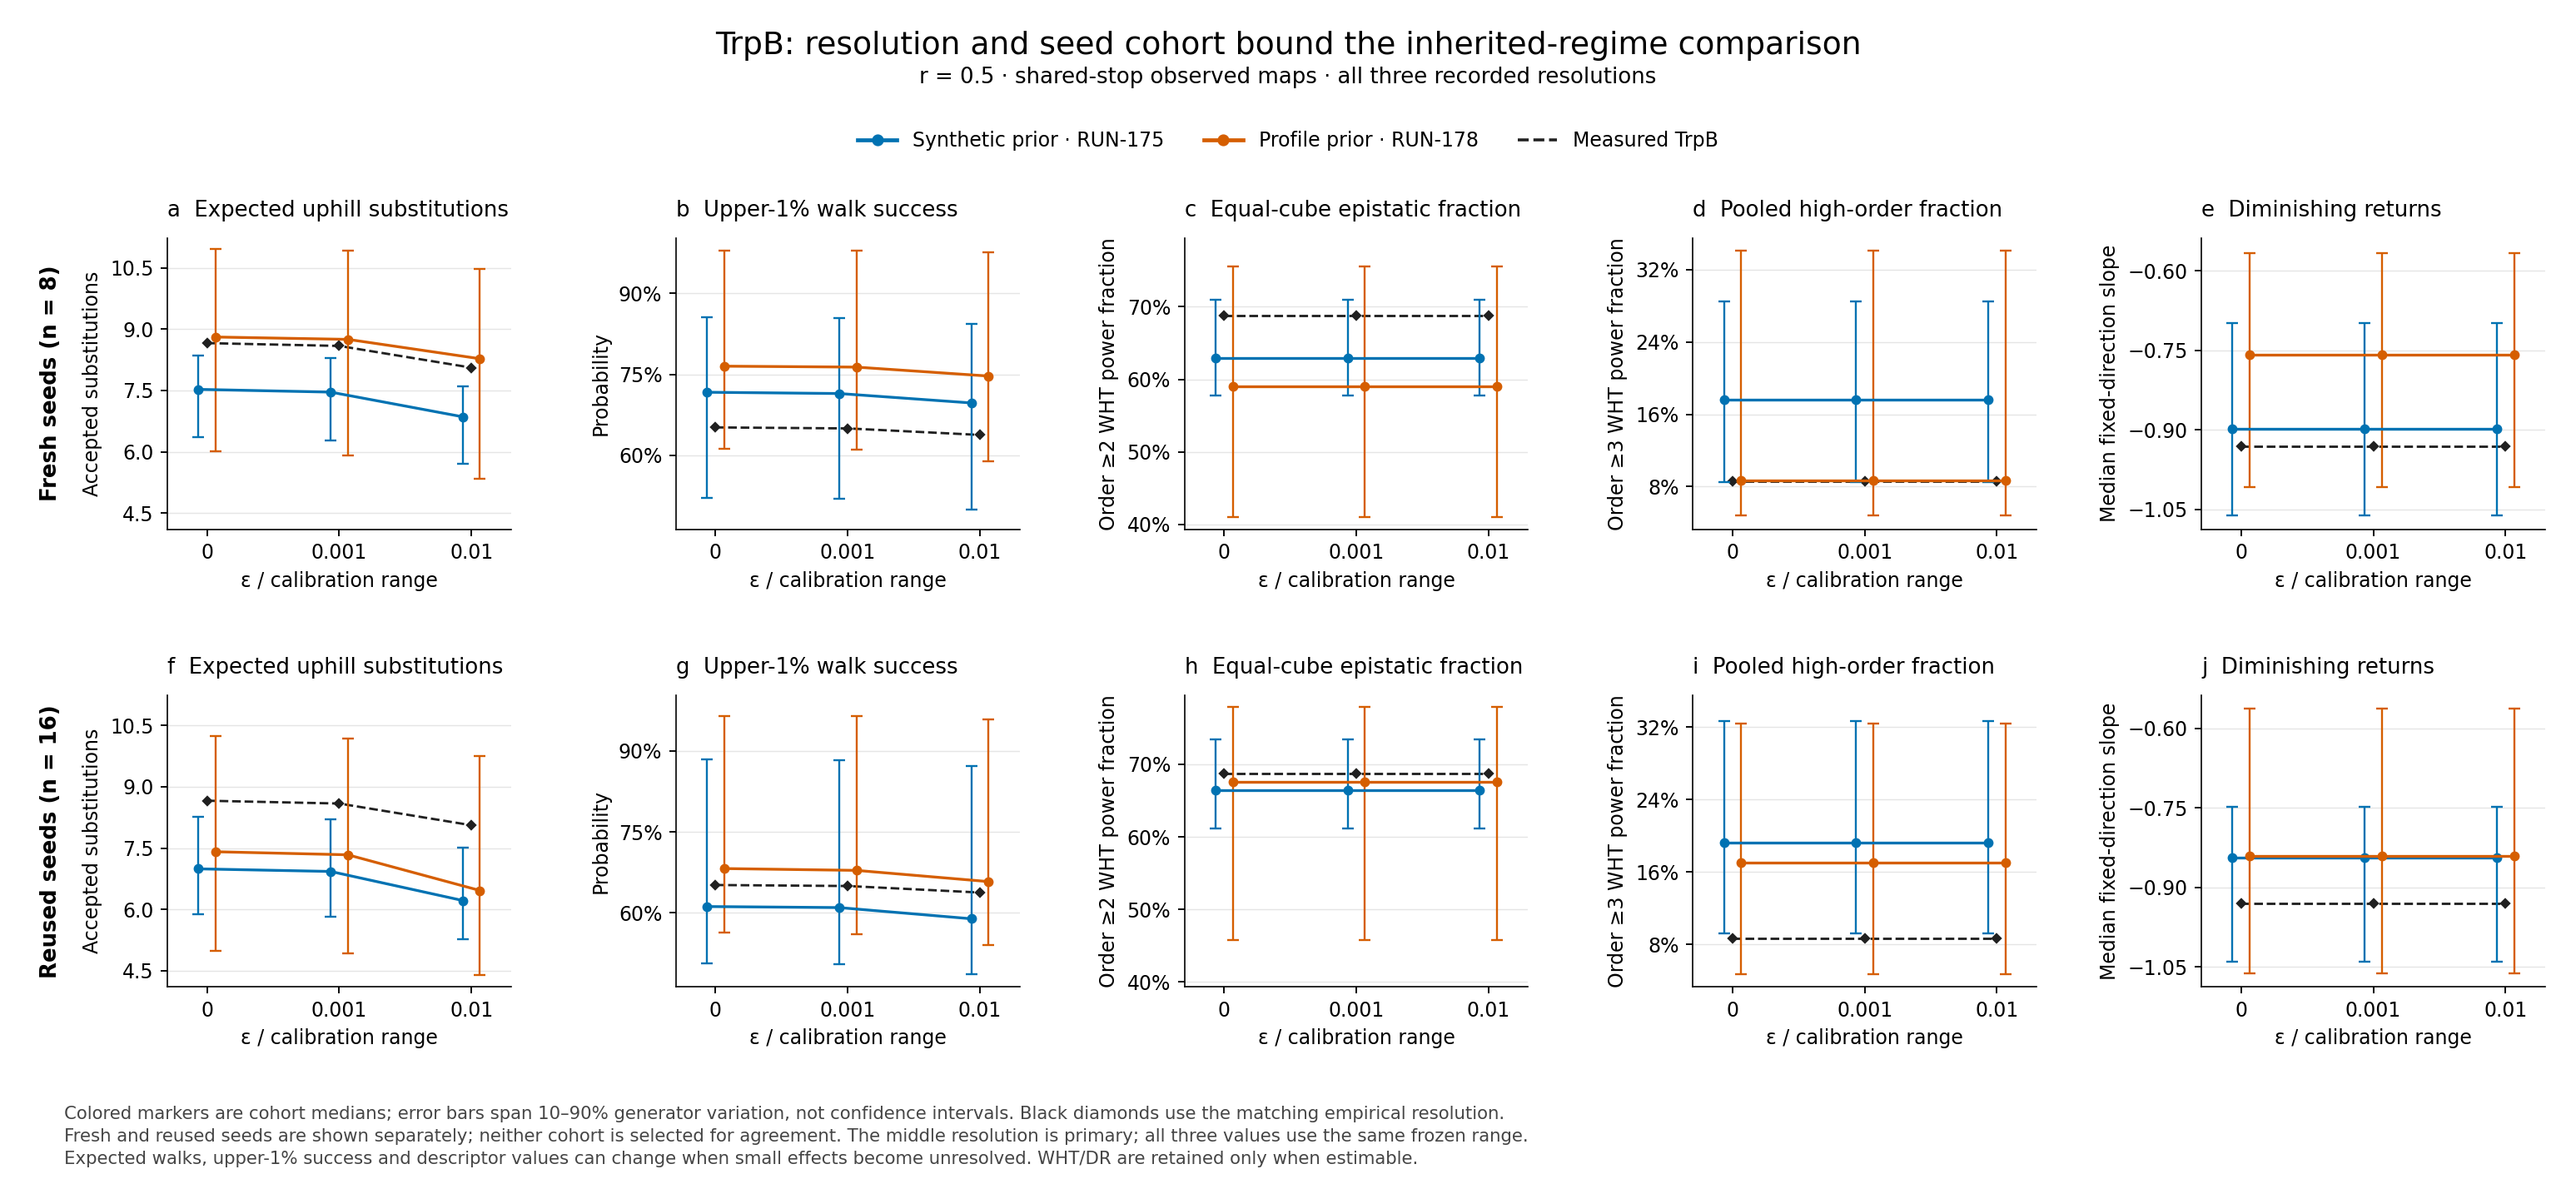

In [6]:
display(Image(filename=str(plots.robustness(data, analysis.FIGURES))))

## Figure 5 — Better calibration loss does not establish better unfitted behavior

The readout was fitted only to fitness quantiles, mean local fitness SD and near-floor mass. At inherited r = 0.5/shared-stop, the objective improves **0.0694 → 0.0392**, mostly through the quantile term. This does not imply improvement in the unfitted graph and epistasis descriptors in Figures 1–3. The no-noise objective is worse with the profile at every tested strength.

Confirmation local SD measures transfer of a descriptor that was fitted on separate calibration cubes; it is not a wholly new type of diagnostic. The availability panels show where WHT fractions or mutation slopes have usable denominators. Unavailable quantities stay missing, not zero. Every differential-evolution search reached the original 60-iteration budget: the fits are reproducible finite-budget solutions, not proven optima.

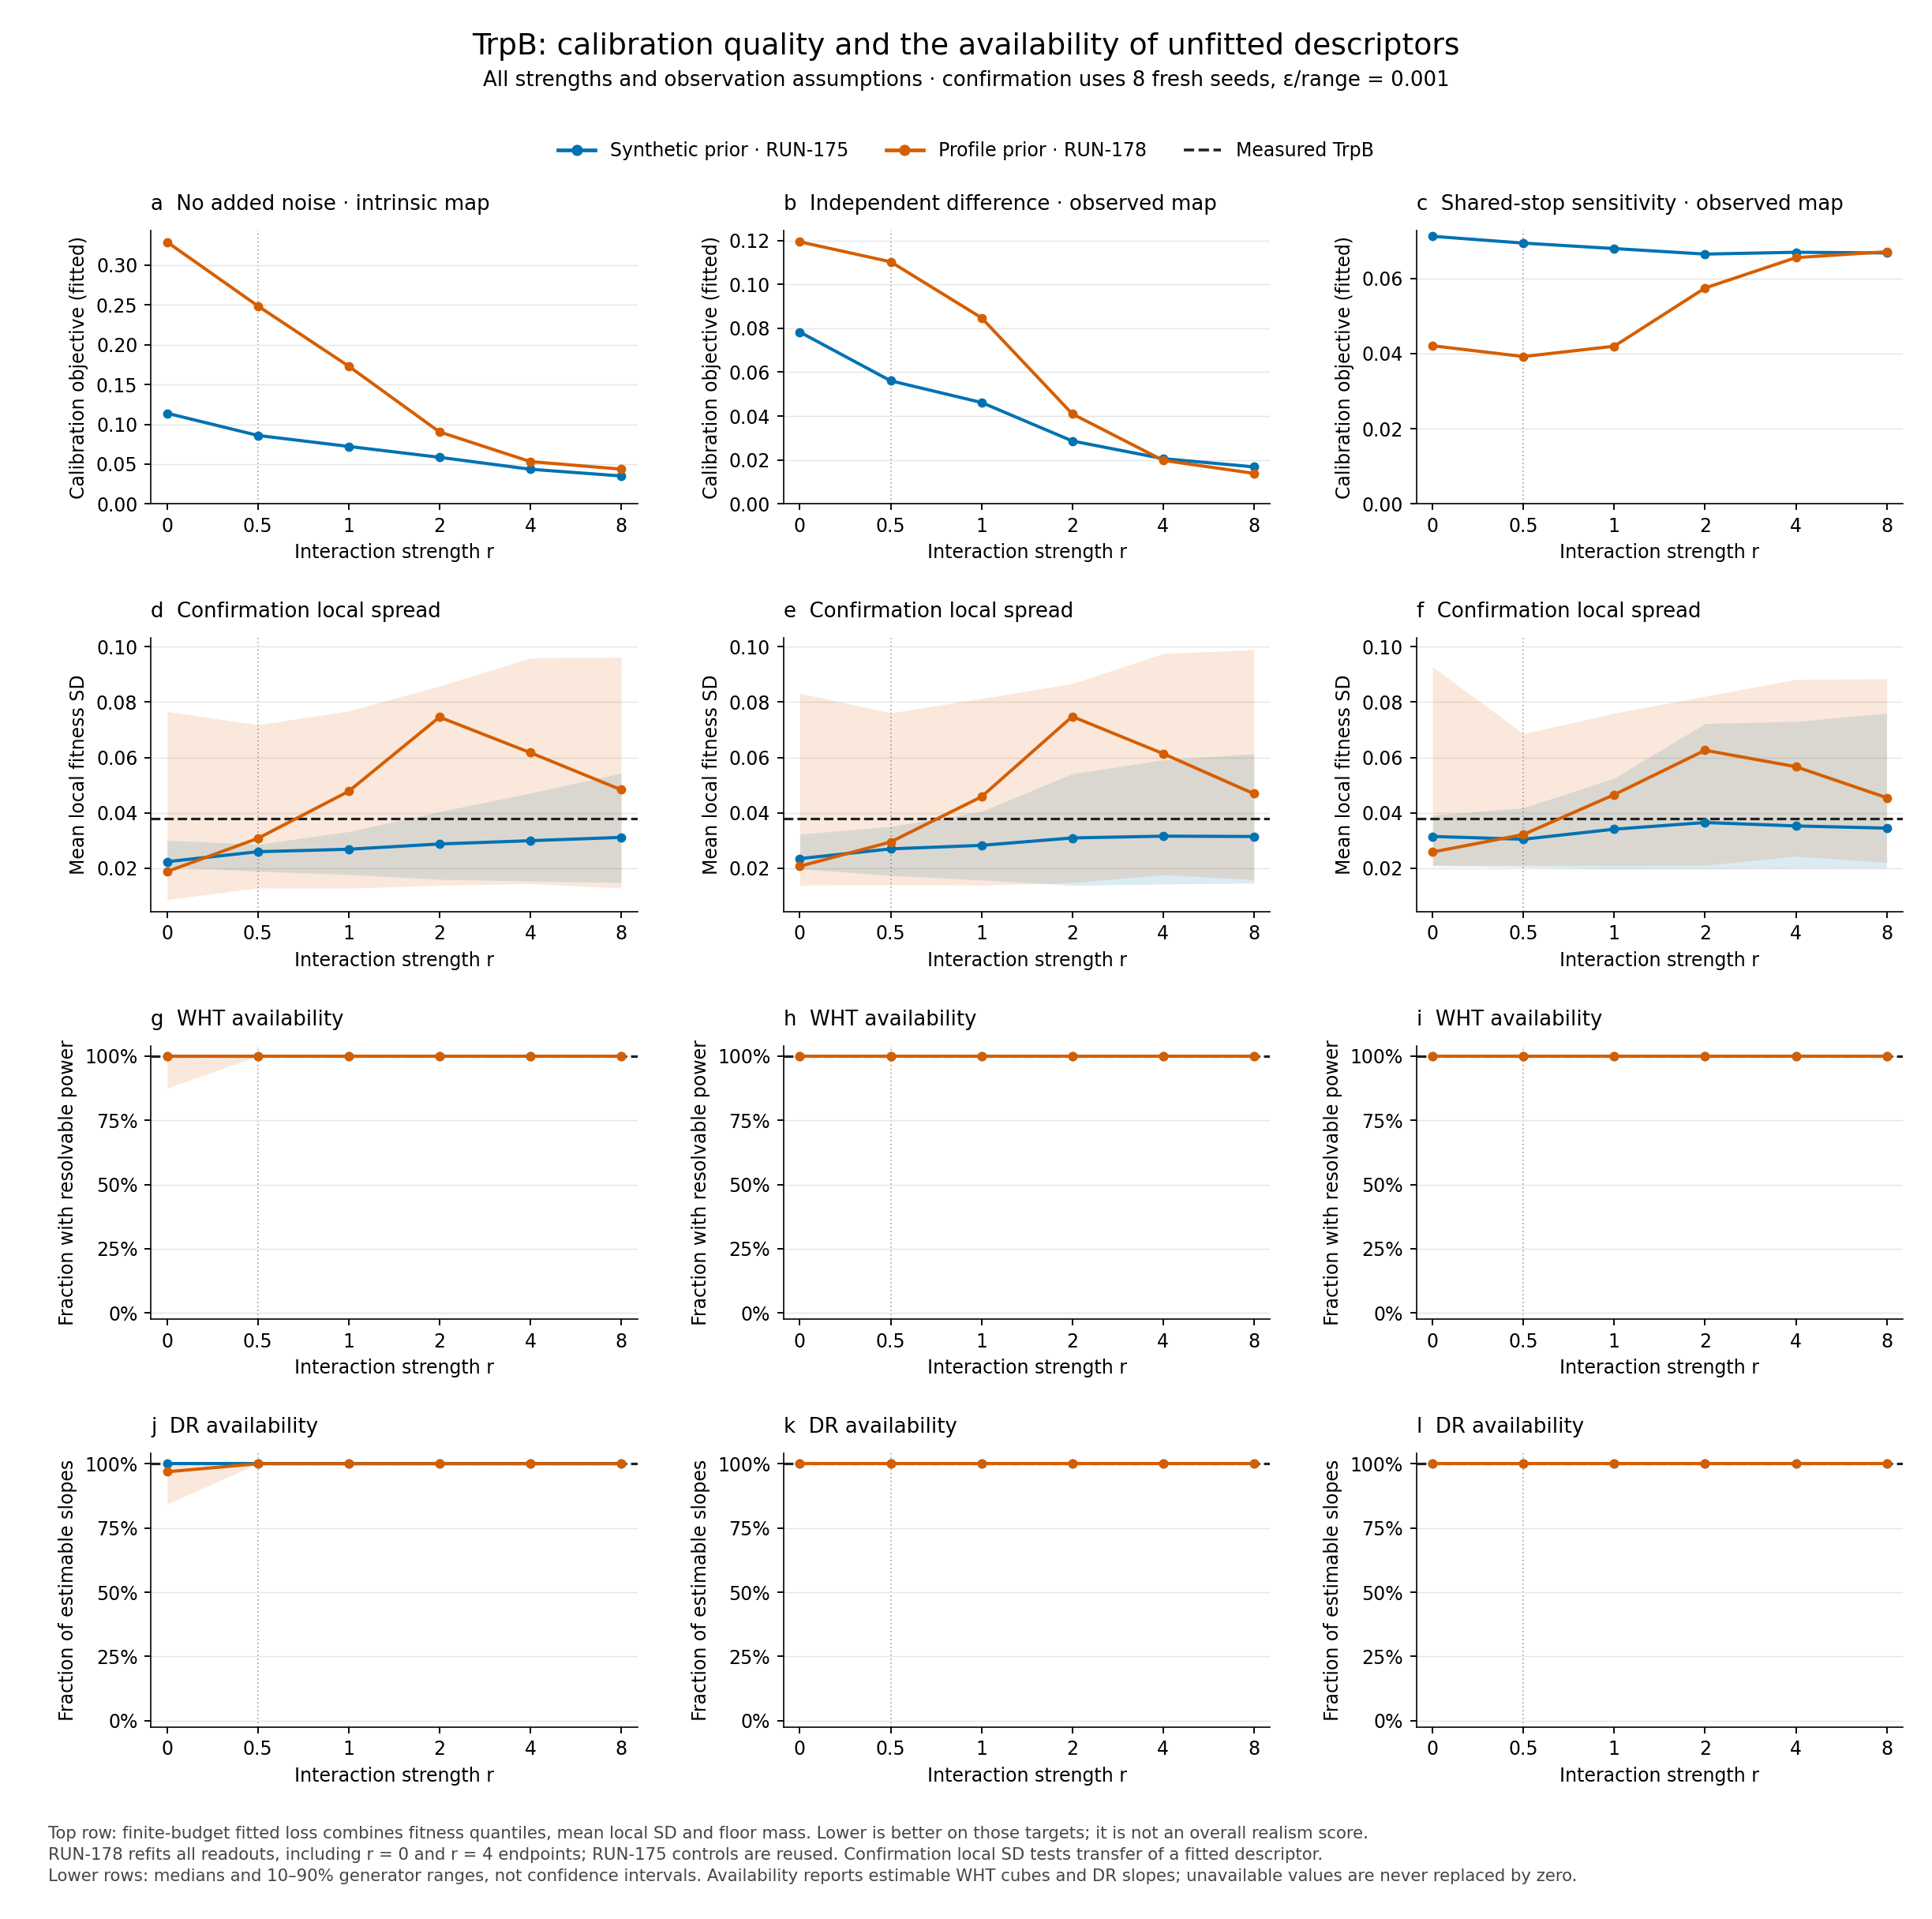

In [7]:
display(Image(filename=str(plots.calibration(data, fits, analysis.FIGURES))))

## Numerical reference for the inherited setting

This table keeps the empirical target and both priors on their original scales. “Profile closer” counts paired fresh seeds with smaller absolute error. The same count accompanies each prior row because it compares the pair.

In [8]:
reference = inherited.loc[inherited.cohort.eq('fresh'),
    ['label', 'prior', 'empirical', 'median', 'q10', 'q90', 'closer', 'n_pairs']].copy()
reference = reference.rename(columns={'label':'Descriptor', 'prior':'Prior', 'empirical':'Measured',
    'median':'Median', 'q10':'10th percentile', 'q90':'90th percentile', 'closer':'Profile closer', 'n_pairs':'Paired seeds'})
display(reference.round(4).reset_index(drop=True))
print('Full tables:', analysis.TABLES)

,Descriptor,Prior,Measured,Median,10th percentile,90th percentile,Profile closer,Paired seeds
0,Uphill walk length,Profile,8.5887,8.7491,5.9044,10.9184,2,8
1,Top-1% success,Profile,0.6498,0.7634,0.6099,0.9787,5,8
2,Equal-cube epistatic power fraction,Profile,0.6876,0.5904,0.4106,0.7553,2,8
3,Equal-cube high-order power fraction,Profile,0.3156,0.2261,0.1798,0.3734,4,8
4,Pooled epistatic power fraction,Profile,0.3297,0.4054,0.2344,0.7137,5,8
5,Pooled high-order power fraction,Profile,0.0862,0.0869,0.0478,0.3403,4,8
6,Sign epistasis,Profile,0.6510,0.5938,0.5161,0.7010,1,8
7,Median diminishing-returns slope,Profile,-0.9306,-0.7578,-1.0074,-0.5671,3,8
8,Confirmation local fitness SD,Profile,0.0379,0.0322,0.0211,0.0685,3,8
9,Uphill walk length,Synthetic,8.5887,7.4591,6.2828,8.2901,2,8


Full tables: /Users/matthewspence/Documents/Documents/project-adapt-env/analyses/2026-11-19_ANA-070_run-178-trpb-profile-prior-versus-synthetic-control/tables


## What the comparison supports

The model now has explicit biological amino-acid preferences, and that change measurably alters its calibrated landscapes. It does **not** show consistent improvement over the fully synthetic prior in resemblance to the measured TrpB descriptors. Selected median agreements improve; other descriptors and many paired seeds worsen. A single favorable plot or a lower fitted objective would give an incomplete account.

The prior comes from the original authors' frequency table, rounded to 0.001, with non-gap conditioning and fixed 1% uniform smoothing. The archived raw alignment was unusable; sequence weights and effective sample size are unknown. The seed-specific reference sequences remain computational centering anchors, not biological wild type or consensus. Four TrpB sites, previously examined empirical data and an explicit observation sensitivity limit the interpretation. This analysis does not test pLM performance, active-learning algorithms, natural-sequence prediction, coevolutionary couplings or transfer to other proteins.

RUN-178 used the exact recorded Python/numerical package versions on macOS/Apple Clang, while RUN-175 ran on Linux. Independent audits reproduce all empirical graph values and match paired interaction fields to numerical precision. Platform differences remain recorded; they are not asserted away. The notebook execution environment is saved in `tables/analysis_environment.json`.